<div dir="rtl">

# الحلقة 4 (مشروع): أول agent متدرب، من الصفر لحد الهبوط

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mmmohamedaaashraf/deep-rl-arabic/blob/main/ep04-first-trained-agent/ep04_first_trained_agent.ipynb)

**سلسلة Deep RL بالعربي**، مبنية على [كورس Hugging Face Deep RL](https://huggingface.co/learn/deep-rl-course) (Unit 1 hands-on: Train your first Deep RL Agent)،
ومكتبة [Stable-Baselines3](https://stable-baselines3.readthedocs.io).

### إحنا فين؟
- **الحلقة 1:** الـ RL loop: الـ agent بياخد state، يختار action، والـ environment ترجعله reward و state جديدة. الـ agent العشوائي وقع.
- **الحلقة 2:** الـ return والـ discounting: الـ γ بيحدد الـ agent بيبص لقدام قد إيه (حوالي 1/(1-γ) خطوة).
- **الحلقة 3:** الـ exploration ضد الـ exploitation، والـ MDP، والفرق بين الـ deterministic والـ stochastic policy.
- **النهارده (مشروع):** نجمع كل ده في مشروع واحد كامل: ندرّب agent بـ **PPO** يهبط المركبة، ونقيّمه صح بالأرقام والصورة.
- **الحلقة الجاية:** يونيت 2: الـ value functions ومعادلة Bellman.
</div>

<div dir="rtl">

## المشروع في سطرين
- **المشكلة:** مركبة في LunarLander لازم تهبط بين العلمين، بأقل بنزين، من غير ما تقع.
- **شرط النجاح (شهادة كورس Hugging Face):** `mean_reward - std_reward >= 200` على 10 حلقات تقييم.
  طرحنا الـ std عشان الـ agent لازم يكون **ثابت** مش بس شاطر في المتوسط.
- **شرطنا إحنا (أصعب):** نفس الحساب على **100 seed** الـ agent عمره ما شافها، ونعدّ كام مرة هبط فعلاً.

## خريطة المشروع، وليه الترتيب ده بالذات
| # | الخطوة | ليه هنا؟ | المفهوم من يونيت 1 |
|---|--------|---------|-------------------|
| 1 | التجهيز وتثبيت الإصدارات | الكود لازم يشتغل بكرة زي النهارده | - |
| 2 | نفهم الـ environment | مينفعش تحل مشكلة مش فاهمها | state, action, reward (حلقة 1) |
| 3 | نقيس الـ baselines | من غير نقطة بداية مش هتعرف التدريب عمل فرق | return (حلقة 2) |
| 4 | 16 environment مع بعض | خبرة أكتر ومتنوعة في نفس الوقت | episodic tasks |
| 5 | نبني الموديل ونفهم كل رقم | كل hyperparameter وراه سبب | γ (حلقة 2)، exploration (حلقة 3) |
| 6 | التدريب و learning curve | نشوف التعلم بيحصل قدامنا | reward hypothesis |
| 7 | حفظ وتحميل | التدريب غالي، منعيدوش | - |
| 8 | التقييم الصح | التقييم الغلط بيكدب عليك | deterministic ضد stochastic (حلقة 3) |
| 9 | فيديو قبل وبعد | دليل بالصورة جنب الأرقام | - |
| 10 | debugging tips | الأخطاء اللي الناس بتقع فيها | - |

**قاعدة المشروع كله:** أي رقم هنقوله لازم يطلع من الكود ده نفسه.
</div>

<div dir="rtl">

## 1) التجهيز
بنثبّت **نفس الإصدارات بالظبط** اللي اتنفذت بيها النوتبوك دي (gymnasium 1.4.0، stable-baselines3 2.9.2).
لو سبت كل حاجة على آخر إصدار، ممكن الكود يبوظ بعد شهر من غير ما تعرف السبب (هنشوف مثال حقيقي في الخطوة 2).
</div>

In [1]:
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "swig"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "gymnasium[box2d]==1.4.0", "stable-baselines3==2.9.2", "imageio[ffmpeg]"], check=True)

import os, time, json, platform
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
import stable_baselines3 as sb3
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.callbacks import BaseCallback
import imageio
from IPython.display import Video, display

print("python           :", platform.python_version())
print("gymnasium        :", gym.__version__)
print("stable-baselines3:", sb3.__version__)
print("torch            :", torch.__version__)
print("GPU              :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

ENV_ID = "LunarLander-v3"
TRAIN_SEED = 0                       # seed of the training environments and of the network weights
EVAL_SEEDS = list(range(1000, 1100))  # 100 landings the agent never trains on
OUT = Path("ep04_outputs"); (OUT / "checkpoints").mkdir(parents=True, exist_ok=True)

python           : 3.12.16
gymnasium        : 1.4.0
stable-baselines3: 2.9.2
torch            : 2.15.0+cu132
GPU              : NVIDIA GeForce RTX 4060 Laptop GPU


<div dir="rtl">

## 2) نفهم الـ environment قبل ما ندرّب أي حاجة
أول سؤال في أي مشروع RL: الـ agent **بيشوف** إيه، و**يقدر يعمل** إيه، و**بيتحاسب** على إيه؟
</div>

In [2]:
env = gym.make(ENV_ID)
print("observation_space:", env.observation_space)
print("action_space     :", env.action_space)
print("max_episode_steps:", env.spec.max_episode_steps)
print("reward_threshold :", env.spec.reward_threshold)

obs, info = env.reset(seed=EVAL_SEEDS[0])
OBS_NAMES = ["x", "y", "vx", "vy", "angle", "angular_vel", "left_leg", "right_leg"]
print("\nfirst state (8 numbers):")
for name, value in zip(OBS_NAMES, obs):
    print(f"  {name:12s} {value:+.3f}")

observation_space: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
action_space     : Discrete(4)
max_episode_steps: 1000
reward_threshold : 200

first state (8 numbers):
  x            -0.005
  y            +1.422
  vx           -0.502
  vy           +0.494
  angle        +0.006
  angular_vel  +0.114
  left_leg     +0.000
  right_leg    +0.000


<div dir="rtl">

الـ **state** هنا 8 أرقام: المكان، السرعة، الزاوية، وكل رجل لامسة الأرض ولا لأ.
الـ **actions** أربعة بس (discrete):
`0` ماتعملش حاجة · `1` الموتور الجانبي الشمال · `2` الموتور الرئيسي · `3` الموتور الجانبي اليمين.

الـ **reward** في كل خطوة (من Gymnasium docs): بيزيد لما المركبة تقرب وتبطّأ وتفضل معدولة،
**+10** لكل رجل تلمس الأرض، **0.3-** لكل frame الموتور الرئيسي شغال و **0.03-** للجانبي،
وفي الآخر **+100** لو هبطت واستقرت أو **100-** لو وقعت. الحلقة تتقفل بعد 1000 خطوة لو ماخلصتش.

نجرب خطوة واحدة عشان نشوف الـ loop بتاعة حلقة 1 بعنينا:
</div>

In [3]:
ACTIONS = {0: "nothing", 1: "left engine", 2: "main engine", 3: "right engine"}
obs, info = env.reset(seed=EVAL_SEEDS[0])
for a in [0, 2]:
    obs, reward, terminated, truncated, info = env.step(a)
    print(f"action {a} ({ACTIONS[a]:12s}) -> reward {reward:+.3f} | terminated={terminated} truncated={truncated}")
env.close()

action 0 (nothing     ) -> reward +0.213 | terminated=False truncated=False
action 2 (main engine ) -> reward -3.022 | terminated=False truncated=False


<div dir="rtl">

**انتبه (أول debugging tip):** كورس Hugging Face الأصلي مكتوب على `LunarLander-v2`. في الإصدارات الجديدة من gymnasium الاسم ده اتشال.
لو نسخت الكود القديم زي ما هو هيقف عندك هنا:
</div>

In [4]:
import warnings
try:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        gym.make("LunarLander-v2")
except Exception as e:
    print(type(e).__name__, "->", str(e)[:160])

DeprecatedEnv -> Environment version v2 for `LunarLander` is deprecated. Please use `LunarLander-v3` instead.


<div dir="rtl">

## 3) الـ baselines: نقطة البداية
قبل ما ندرّب، لازم نعرف "الوحش" بيجيب كام. هنقيس اتنين:
- **agent عشوائي** (زي حلقة 1).
- **agent مابيعملش حاجة** (action 0 على طول): قاعدة غبية بس ساعات بتغلب العشوائي.

ونقيسهم على **نفس الـ 100 seed** اللي هنقيّم عليها الـ agent المتدرب في الآخر، عشان المقارنة تبقى عادلة.
`play()` بتلعب حلقة كاملة وترجع الـ return، وعدد الخطوات، وإزاي الحلقة خلصت.
</div>

In [5]:
def play(policy, seed, record=False):
    """One full episode. policy(obs, env) -> action. Returns (return, steps, outcome, frames)."""
    env = gym.make(ENV_ID, render_mode="rgb_array" if record else None)
    obs, _ = env.reset(seed=seed)
    env.action_space.seed(seed)
    total, steps, frames, done = 0.0, 0, [], False
    while not done:
        if record:
            frames.append(env.render())
        obs, r, terminated, truncated, _ = env.step(policy(obs, env))
        total += float(r); steps += 1
        done = terminated or truncated
    if record:
        frames.append(env.render())
    env.close()
    # LunarLander ends with exactly +100 (landed and at rest) or -100 (crashed / flew out)
    outcome = "landed" if r == 100 else ("crashed" if r == -100 else "timeout")
    return total, steps, outcome, frames


def evaluate_many(policy, seeds=EVAL_SEEDS):
    runs = [play(policy, s) for s in seeds]
    returns = np.array([r[0] for r in runs])
    outcomes = [r[2] for r in runs]
    return {"returns": returns, "mean": returns.mean(), "std": returns.std(),
            "score": returns.mean() - returns.std(),
            "landed": outcomes.count("landed"), "crashed": outcomes.count("crashed"),
            "timeout": outcomes.count("timeout"), "steps": float(np.mean([r[1] for r in runs]))}


def show(name, s):
    print(f"{name:22s} mean {s['mean']:+7.1f}  std {s['std']:5.1f}  mean-std {s['score']:+7.1f} | "
          f"landed {s['landed']:3d}  crashed {s['crashed']:3d}  timeout {s['timeout']:3d} | avg steps {s['steps']:6.1f}")


random_policy = lambda obs, env: env.action_space.sample()
nothing_policy = lambda obs, env: 0

base_random = evaluate_many(random_policy)
base_nothing = evaluate_many(nothing_policy)
show("random", base_random)
show("do nothing", base_nothing)

random                 mean  -200.8  std 109.1  mean-std  -309.9 | landed   0  crashed  99  timeout   1 | avg steps  105.5
do nothing             mean  -131.1  std  50.2  mean-std  -181.3 | landed   0  crashed 100  timeout   0 | avg steps   73.2


<div dir="rtl">

## 4) 16 environment شغالين مع بعض
الـ PPO **on-policy**: بيتعلم بس من خبرة جمعها بالـ policy الحالية، وبعد كل تحديث بيرمي الخبرة دي ويجمع جديدة.
عشان كده محتاج خبرة كتير **وبسرعة**. الحل: نشغّل 16 نسخة من البيئة مع بعض، كل واحدة بـ seed مختلف،
فالـ agent يشوف 16 موقف مختلف في نفس اللحظة.

`make_vec_env` كمان بيلف كل بيئة بـ `Monitor`، وده اللي بيسجّل الـ return والطول بتاع كل حلقة خلصت (هنحتاجه للـ learning curve).
</div>

In [6]:
N_ENVS = 16
vec_env = make_vec_env(ENV_ID, n_envs=N_ENVS, seed=TRAIN_SEED)
obs = vec_env.reset()
print(type(vec_env).__name__, "| obs shape:", obs.shape, " <- 16 environments x 8 numbers")
actions = np.array([vec_env.action_space.sample() for _ in range(N_ENVS)])
obs, rewards, dones, infos = vec_env.step(actions)
print("one step for all 16 -> rewards shape:", rewards.shape)
print("is each env wrapped in Monitor?", type(vec_env.envs[0]).__name__)

DummyVecEnv | obs shape: (16, 8)  <- 16 environments x 8 numbers
one step for all 16 -> rewards shape: (16,)
is each env wrapped in Monitor? Monitor


<div dir="rtl">

## 5) الموديل: PPO، وكل رقم فيه ليه
| الـ hyperparameter | القيمة | معناه | ليه القيمة دي؟ |
|---|---|---|---|
| `n_steps` | 1024 | كل بيئة تلعب 1024 خطوة قبل كل تحديث | 1024 × 16 = 16,384 خطوة خبرة لكل تحديث |
| `batch_size` | 64 | الخبرة بتتقسم لدفعات صغيرة | تحديثات أكتر وأهدى |
| `n_epochs` | 4 | يعدّي على نفس الخبرة 4 مرات | يستفيد منها أكتر قبل ما يرميها |
| `gamma` | 0.999 | الـ discount (حلقة 2) | الأفق 1/(1-0.999) = **1000 خطوة** = طول الحلقة كله، فالـ +100 بتاعة الهبوط تبان من أول الحلقة |
| `gae_lambda` | 0.98 | إزاي بنقدّر "الـ action دي كانت أحسن من المتوقع قد إيه" | هنشرحه بالتفصيل في Actor-Critic |
| `ent_coef` | 0.01 | مكافأة صغيرة على التنويع | ده الـ **exploration** بتاع حلقة 3: يمنع الـ agent يقفل على حركة واحدة بدري |

القيم دي هي اللي كورس Hugging Face بيبدأ بيها، وهي قريبة من الـ tuned values في RL Zoo.

**CPU ولا GPU؟** المنطقي إن الـ GPU أسرع، بس الشبكة هنا صغيرة جداً والـ PPO بيقضي أغلب وقته في تشغيل البيئة.
بدل ما نخمّن، **نقيس**:
</div>

In [7]:
PPO_KW = dict(n_steps=1024, batch_size=64, n_epochs=4, gamma=0.999,
              gae_lambda=0.98, ent_coef=0.01, seed=TRAIN_SEED, verbose=0)

def speed_test(device, steps=2 * 1024 * N_ENVS):
    env = make_vec_env(ENV_ID, n_envs=N_ENVS, seed=TRAIN_SEED)
    m = PPO("MlpPolicy", env, device=device, **PPO_KW)
    t0 = time.time(); m.learn(steps); dt = time.time() - t0
    env.close()
    return steps / dt

speeds = {"cpu": speed_test("cpu")}
if torch.cuda.is_available():
    speeds["cuda"] = speed_test("cuda")
for d, v in speeds.items():
    print(f"{d:5s}: {v:7.0f} steps/second")
DEVICE = max(speeds, key=speeds.get)
print("training on:", DEVICE)

.../lib/python3.12/site-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


cpu  :    2672 steps/second
cuda :    3294 steps/second
training on: cuda


In [8]:
model = PPO("MlpPolicy", vec_env, device=DEVICE, **PPO_KW)
print(model.policy)
n_params = sum(p.numel() for p in model.policy.parameters())
rollout = model.n_steps * N_ENVS
print(f"\nparameters          : {n_params:,}")
print(f"experience per update: {model.n_steps} x {N_ENVS} = {rollout:,} steps")
print(f"gradient steps/update: {rollout // model.batch_size} minibatches x {model.n_epochs} epochs = {rollout // model.batch_size * model.n_epochs:,}")
print(f"gamma horizon        : 1/(1-{model.gamma}) = {1 / (1 - model.gamma):.0f} steps")

ActorCriticPolicy(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (pi_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (vf_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (mlp_extractor): MlpExtractor(
    (policy_net): Sequential(
      (0): Linear(in_features=8, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
    (value_net): Sequential(
      (0): Linear(in_features=8, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
  )
  (action_net): Linear(in_features=64, out_features=4, bias=True)
  (value_net): Linear(in_features=64, out_features=1, bias=True)
)

parameters          : 9,797
experience per update: 1024 x 16 = 16,384 steps
gradient steps/update: 256 minibatches x 4 epochs = 1,024

<div dir="rtl">

جوا الموديل شبكتين صغيرين: **policy net** (الـ actor) بتطلع احتمال لكل action من الأربعة،
و **value net** (الـ critic) بتقدّر الـ return المتوقع من الـ state دي. الاتنين بياخدوا نفس الـ 8 أرقام.

نبص جوا "مخ" الـ agent **قبل** التدريب: على نفس أول state، كل action احتمالها قد إيه؟
</div>

In [9]:
def action_probs(model, obs):
    obs_t, _ = model.policy.obs_to_tensor(obs)
    with torch.no_grad():
        return model.policy.get_distribution(obs_t).distribution.probs[0].cpu().numpy()

probe_obs, _ = gym.make(ENV_ID).reset(seed=EVAL_SEEDS[0])
probs_before = action_probs(model, probe_obs)
for a, p in enumerate(probs_before):
    print(f"  {a} {ACTIONS[a]:12s} {100 * p:5.1f}%")

  0 nothing       25.1%
  1 left engine   25.0%
  2 main engine   24.9%
  3 right engine  25.0%


<div dir="rtl">

## 6) التدريب
هندرّب **1,000,000 خطوة**. وعشان نشوف التعلم بيحصل، عملنا `callback` صغير بيعمل 3 حاجات:
1. يسجّل الـ return بتاع كل حلقة بتخلص (من الـ `Monitor`) عشان نرسم الـ learning curve.
2. يحفظ نسخة من الموديل عند خطوات معينة (checkpoints)، عشان نقارن الـ agent وهو بيتعلم.
3. يطبع ملخص كل ~100 ألف خطوة: متوسط آخر 100 حلقة، والوقت.
</div>

In [10]:
class TrainingLog(BaseCallback):
    def __init__(self, save_at, folder, print_every):
        super().__init__()
        self.save_at, self.folder, self.print_every = sorted(save_at), Path(folder), print_every
        self.episodes, self.checkpoints, self.next_print = [], {}, print_every

    def _save(self, mark):
        path = self.folder / f"ppo_{mark:07d}"
        self.model.save(path)
        self.checkpoints[mark] = str(path) + ".zip"

    def _on_training_start(self):
        self.t0 = time.time()
        self._save(0)                                   # the untrained brain

    def _on_step(self):
        for info in self.locals["infos"]:
            if "episode" in info:                       # an episode just ended in one of the 16 envs
                self.episodes.append((self.num_timesteps, info["episode"]["r"], info["episode"]["l"]))
        while self.save_at and self.num_timesteps >= self.save_at[0]:
            self._save(self.save_at.pop(0))
        return True

    def _on_rollout_end(self):
        if self.num_timesteps >= self.next_print:
            last = [e[1] for e in self.episodes[-100:]]
            print(f"{self.num_timesteps:>9,} steps | episodes {len(self.episodes):5d} | "
                  f"mean return (last 100) {np.mean(last):+7.1f} | {(time.time() - self.t0) / 60:5.1f} min")
            self.next_print += self.print_every


TOTAL_TIMESTEPS = 1_000_000
log = TrainingLog(save_at=[50000, 100000, 200000, 300000, 500000, 750000], folder=OUT / "checkpoints", print_every=TOTAL_TIMESTEPS // 10)
t0 = time.time()
model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=log)
train_minutes = (time.time() - t0) / 60
print(f"\ndone: {model.num_timesteps:,} steps, {len(log.episodes):,} episodes, {train_minutes:.1f} minutes on {DEVICE}")

  114,688 steps | episodes  1190 | mean return (last 100)   -76.8 |   0.6 min


  212,992 steps | episodes  1959 | mean return (last 100)    -6.8 |   1.3 min


  311,296 steps | episodes  2296 | mean return (last 100)   +22.7 |   2.6 min


  409,600 steps | episodes  2438 | mean return (last 100)   +58.7 |   3.7 min


  507,904 steps | episodes  2548 | mean return (last 100)   +96.0 |   4.7 min


  606,208 steps | episodes  2662 | mean return (last 100)  +104.4 |   5.6 min


  704,512 steps | episodes  2770 | mean return (last 100)  +130.4 |   6.6 min


  802,816 steps | episodes  2869 | mean return (last 100)  +149.5 |   7.5 min


  901,120 steps | episodes  3076 | mean return (last 100)  +243.5 |   8.1 min


1,015,808 steps | episodes  3434 | mean return (last 100)  +250.3 |   9.0 min



done: 1,015,808 steps, 3,434 episodes, 9.1 minutes on cuda


<div dir="rtl">

**ملاحظة:** الرقم النهائي أكبر شوية من المطلوب لأن الـ PPO بيخلّص الـ rollout اللي بدأه (16,384 خطوة في كل مرة).

### الـ learning curve
كل نقطة حلقة واحدة من الـ 16 بيئة. الخط التقيل متوسط آخر 100 حلقة.
</div>

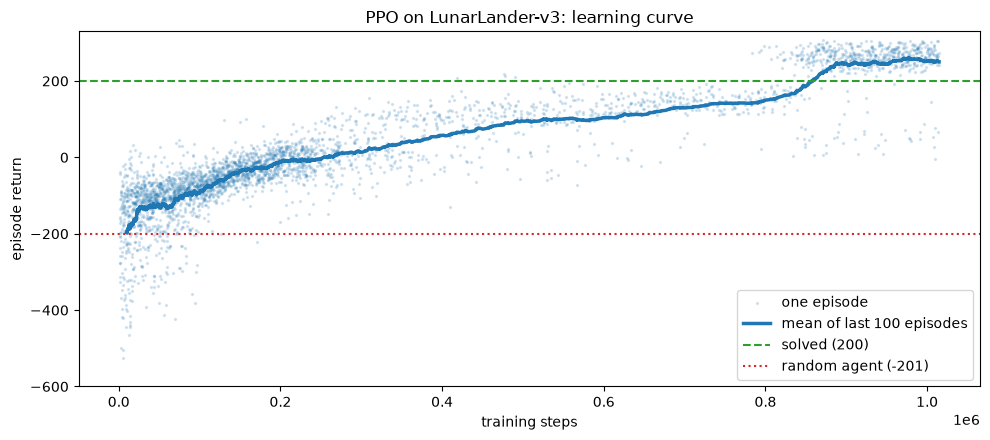

training mean (last 100 episodes) at the end: 250.3
first time the 100-episode mean crossed 200 : 858592 steps


In [11]:
ep = np.array(log.episodes)
steps_ep, ret_ep = ep[:, 0], ep[:, 1]
rolling = np.convolve(ret_ep, np.ones(100) / 100, mode="valid")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(steps_ep, ret_ep, s=2, alpha=0.15, color="tab:blue", label="one episode")
ax.plot(steps_ep[99:], rolling, color="tab:blue", lw=2.5, label="mean of last 100 episodes")
ax.axhline(200, color="tab:green", ls="--", label="solved (200)")
ax.axhline(base_random["mean"], color="tab:red", ls=":", label=f"random agent ({base_random['mean']:.0f})")
ax.set_xlabel("training steps"); ax.set_ylabel("episode return"); ax.set_ylim(-600, 330)
ax.legend(loc="lower right"); ax.set_title("PPO on LunarLander-v3: learning curve")
plt.tight_layout(); plt.savefig(OUT / "learning_curve.png", dpi=150); plt.show()

first_200 = next((int(s) for s, r in zip(steps_ep[99:], rolling) if r >= 200), None)
print("training mean (last 100 episodes) at the end:", round(float(rolling[-1]), 1))
print("first time the 100-episode mean crossed 200 :", first_200, "steps")

<div dir="rtl">

## 7) حفظ وتحميل
التدريب أخد وقت، فأول حاجة نعملها نحفظه. وبعدين **نتأكد** إن النسخة اللي اتحملت هي هي:
نسأل الموديلين نفس السؤال ونقارن الإجابة.
</div>

In [12]:
model.save(OUT / "ppo-LunarLander-v3")
size_kb = (OUT / "ppo-LunarLander-v3.zip").stat().st_size / 1024
before = model.predict(probe_obs, deterministic=True)[0]
del model
model = PPO.load(OUT / "ppo-LunarLander-v3", device=DEVICE)
after = model.predict(probe_obs, deterministic=True)[0]
print(f"saved file: {size_kb:.0f} KB")
print("same action before and after loading:", int(before) == int(after))

saved file: 147 KB
same action before and after loading: True


<div dir="rtl">

## 8) التقييم الصح
3 قواعد:
1. نقيّم على **بيئة منفصلة** ملفوفة بـ `Monitor`، مش على بيئة التدريب.
2. نخلي الـ policy **deterministic**: ياخد الـ action الأعلى احتمال (حلقة 3).
3. نستخدم **seeds ثابتة**، عشان أي حد يعيد التجربة يطلع نفس الأرقام.

### أ) طريقة كورس Hugging Face: 10 حلقات
</div>

In [13]:
eval_env = DummyVecEnv([lambda: Monitor(gym.make(ENV_ID))])
eval_env.seed(2000)
mean_reward, std_reward = evaluate_policy(model, eval_env, n_eval_episodes=10, deterministic=True)
hf_score = mean_reward - std_reward
print(f"mean_reward = {mean_reward:.2f} +/- {std_reward:.2f}")
print(f"mean - std  = {hf_score:.2f}  ->  {'PASSED' if hf_score >= 200 else 'NOT YET'} (needs >= 200)")

mean_reward = 260.77 +/- 11.98
mean - std  = 248.79  ->  PASSED (needs >= 200)


<div dir="rtl">

### ب) طريقتنا: 100 seed، ونفس الـ seeds بتاعة الـ baselines
</div>

random                 mean  -200.8  std 109.1  mean-std  -309.9 | landed   0  crashed  99  timeout   1 | avg steps  105.5
do nothing             mean  -131.1  std  50.2  mean-std  -181.3 | landed   0  crashed 100  timeout   0 | avg steps   73.2
PPO stochastic         mean  +264.5  std  37.5  mean-std  +227.1 | landed  98  crashed   2  timeout   0 | avg steps  303.9
PPO deterministic      mean  +260.0  std  26.7  mean-std  +233.3 | landed  99  crashed   0  timeout   1 | avg steps  332.4


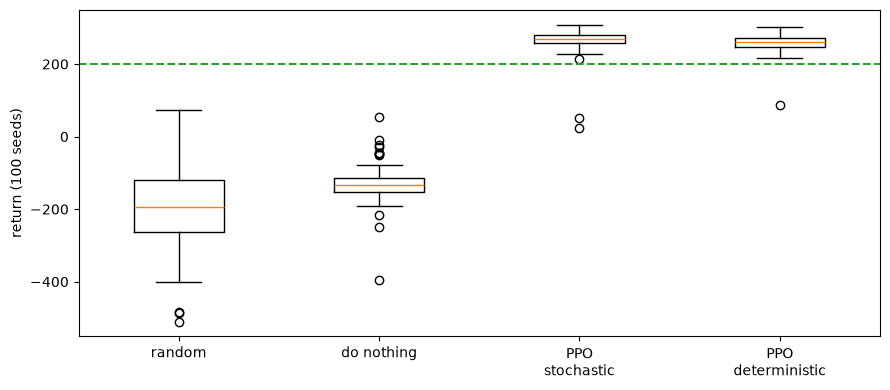

In [14]:
ppo_det = evaluate_many(lambda obs, env: model.predict(obs, deterministic=True)[0])
ppo_sto = evaluate_many(lambda obs, env: model.predict(obs, deterministic=False)[0])
show("random", base_random)
show("do nothing", base_nothing)
show("PPO stochastic", ppo_sto)
show("PPO deterministic", ppo_det)

fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([base_random["returns"], base_nothing["returns"], ppo_sto["returns"], ppo_det["returns"]],
           tick_labels=["random", "do nothing", "PPO\nstochastic", "PPO\ndeterministic"])
ax.axhline(200, color="tab:green", ls="--"); ax.set_ylabel("return (100 seeds)")
plt.tight_layout(); plt.savefig(OUT / "eval_boxplot.png", dpi=150); plt.show()

<div dir="rtl">

### ج) مخ الـ agent بعد التدريب
نفس أول state بتاعة الخطوة 5. قبل التدريب كانت الاحتمالات شبه متساوية:
</div>

In [15]:
probs_after = action_probs(model, probe_obs)
for a in range(4):
    print(f"  {a} {ACTIONS[a]:12s} before {100 * probs_before[a]:5.1f}%  ->  after {100 * probs_after[a]:5.1f}%")

  0 nothing      before  25.1%  ->  after  15.9%
  1 left engine  before  25.0%  ->  after   0.1%
  2 main engine  before  24.9%  ->  after   0.0%
  3 right engine before  25.0%  ->  after  84.0%


<div dir="rtl">

### د) إمتى بالظبط اتعلم؟ نقيّم كل checkpoint
نفس التقييم الـ deterministic، على أول 20 seed، لكل نسخة اتحفظت أثناء التدريب.
</div>

        0 steps | mean  -254.6  mean-std  -319.9 | landed  0/20  crashed 20  timeout  0


   50,000 steps | mean   -48.8  mean-std  -114.6 | landed  0/20  crashed 19  timeout  1


  100,000 steps | mean  -153.7  mean-std  -194.1 | landed  0/20  crashed 20  timeout  0


  200,000 steps | mean  -154.6  mean-std  -195.9 | landed  0/20  crashed 20  timeout  0


  300,000 steps | mean  -126.7  mean-std  -172.6 | landed  0/20  crashed 14  timeout  6


  500,000 steps | mean   +67.3  mean-std   -28.1 | landed 16/20  crashed  4  timeout  0


  750,000 steps | mean  +239.7  mean-std  +220.5 | landed 20/20  crashed  0  timeout  0


1,015,808 steps | mean  +262.8  mean-std  +242.3 | landed 20/20  crashed  0  timeout  0


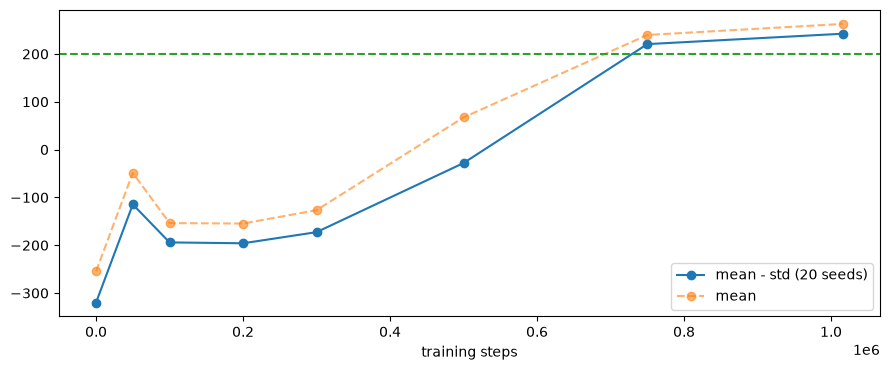

In [16]:
ckpt_rows = []
for mark, path in sorted(log.checkpoints.items()) + [(model.num_timesteps, str(OUT / "ppo-LunarLander-v3.zip"))]:
    m = PPO.load(path, device="cpu")
    s = evaluate_many(lambda obs, env: m.predict(obs, deterministic=True)[0], EVAL_SEEDS[:20])
    ckpt_rows.append({"steps": int(mark), "mean": float(s["mean"]), "std": float(s["std"]),
                      "score": float(s["score"]), "landed": s["landed"], "crashed": s["crashed"], "timeout": s["timeout"]})
    print(f"{mark:>9,} steps | mean {s['mean']:+7.1f}  mean-std {s['score']:+7.1f} | "
          f"landed {s['landed']:2d}/20  crashed {s['crashed']:2d}  timeout {s['timeout']:2d}")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot([r["steps"] for r in ckpt_rows], [r["score"] for r in ckpt_rows], "o-", label="mean - std (20 seeds)")
ax.plot([r["steps"] for r in ckpt_rows], [r["mean"] for r in ckpt_rows], "o--", alpha=0.6, label="mean")
ax.axhline(200, color="tab:green", ls="--"); ax.set_xlabel("training steps"); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "checkpoints.png", dpi=150); plt.show()

<div dir="rtl">

## 9) قبل وبعد: بالصورة
نختار seed الـ agent العشوائي وقع فيها والـ agent المتدرب هبط، ونصوّر الاتنين على **نفس** الـ seed.
وكمان نصوّر بعض الـ checkpoints عشان نشوف الـ agent بيتعلم إزاي.
</div>

In [17]:
FPS = gym.make(ENV_ID).metadata["render_fps"]
det_policy = lambda obs, env: model.predict(obs, deterministic=True)[0]
VIDEO_SEED = next((s for s in EVAL_SEEDS if play(random_policy, s)[2] == "crashed" and play(det_policy, s)[2] == "landed"), EVAL_SEEDS[0])

def record(policy, seed, name):
    ret, steps, outcome, frames = play(policy, seed, record=True)
    imageio.mimsave(OUT / name, frames, fps=FPS, macro_block_size=1)
    print(f"{name:22s} return {ret:+7.1f} | {steps:4d} steps | {outcome}")
    return {"return": ret, "steps": steps, "outcome": outcome}

videos = {"before": record(random_policy, VIDEO_SEED, "before_random.mp4"),
          "after": record(det_policy, VIDEO_SEED, "after_ppo.mp4")}
for mark, path in sorted(log.checkpoints.items()):
    m = PPO.load(path, device="cpu")
    videos[f"ckpt_{mark}"] = record(lambda obs, env: m.predict(obs, deterministic=True)[0], VIDEO_SEED, f"ckpt_{mark:07d}.mp4")
print("video seed:", VIDEO_SEED)

before_random.mp4      return  -163.0 |  124 steps | crashed


after_ppo.mp4          return  +271.6 |  370 steps | landed


ckpt_0000000.mp4       return  -256.5 |  115 steps | crashed


ckpt_0050000.mp4       return  -116.7 |  432 steps | crashed


ckpt_0100000.mp4       return  -113.1 |  320 steps | crashed


ckpt_0200000.mp4       return  -134.3 |  301 steps | crashed


ckpt_0300000.mp4       return  -153.3 |  805 steps | crashed


ckpt_0500000.mp4       return  +172.8 |  843 steps | landed


ckpt_0750000.mp4       return  +245.6 |  506 steps | landed
video seed: 1000


In [18]:
display(Video(str(OUT / "before_random.mp4"), embed=True, width=420))
display(Video(str(OUT / "after_ppo.mp4"), embed=True, width=420))

<div dir="rtl">

## 10) Debugging tips (بأرقام من النوتبوك دي)
</div>

In [19]:
groups = ppo_det["returns"].reshape(10, 10)
group_scores = groups.mean(axis=1) - groups.std(axis=1)
print("1) deterministic vs stochastic (100 seeds):")
print(f"   mean-std {ppo_det['score']:+.1f} vs {ppo_sto['score']:+.1f} | landed {ppo_det['landed']} vs {ppo_sto['landed']}")
print("2) 10 episodes can lie: mean-std on 10 different groups of 10 seeds:")
print(f"   from {group_scores.min():+.1f} to {group_scores.max():+.1f}")
print("3) the training log is not the final score:")
print(f"   training mean (last 100, stochastic, while learning) {rolling[-1]:+.1f} vs deterministic eval {ppo_det['mean']:+.1f}")
under = [r for r in ckpt_rows if r["score"] < 200]
if under:
    print("4) stopping too early: last checkpoint still below 200:")
    print(f"   {under[-1]['steps']:,} steps -> mean-std {under[-1]['score']:+.1f}")

1) deterministic vs stochastic (100 seeds):
   mean-std +233.3 vs +227.1 | landed 99 vs 98
2) 10 episodes can lie: mean-std on 10 different groups of 10 seeds:
   from +189.0 to +254.2
3) the training log is not the final score:
   training mean (last 100, stochastic, while learning) +250.3 vs deterministic eval +260.0
4) stopping too early: last checkpoint still below 200:
   500,000 steps -> mean-std -28.1


<div dir="rtl">

- **جيبت أقل من 200؟** درّب أطول الأول (2 مليون خطوة مثلاً) قبل ما تلعب في الـ hyperparameters، وغيّر حاجة واحدة بس كل مرة.
- **الأرقام بتاعتك مختلفة شوية عن الفيديو؟** طبيعي: الـ GPU والـ CPU وإصدار torch ممكن يغيروا الأرقام شوية. المهم الـ mean - std فوق 200.
- **الـ ep_rew_mean واقف ومبيزيدش؟** اتأكد إن الـ γ مش صغير (0.99 بيخلي الـ +100 بتاعة الهبوط شبه مش باينة من أول الحلقة).

## الخلاصة
1. **افهم الـ environment الأول:** state بـ 8 أرقام، 4 actions، وreward بيكافئ الهبوط ويعاقب على البنزين والوقوع.
2. **قيس baseline** على نفس الـ seeds اللي هتقيّم عليها في الآخر.
3. **16 environment** = خبرة أكتر ومتنوعة للـ PPO اللي بيرمي خبرته بعد كل تحديث.
4. **كل hyperparameter ليه سبب:** γ = 0.999 عشان الأفق يغطي الحلقة كلها، و ent_coef = exploration.
5. **التقييم الصح:** بيئة منفصلة، deterministic، seeds ثابتة، وحلقات كفاية.
6. **احفظ الموديل** واتأكد إن النسخة اللي اتحملت بتدي نفس القرارات.

## تمارين
1. **درّب 300 ألف خطوة بس.** هل بيعدّي الـ 200؟
   *تلميح:* بص على جدول الـ checkpoints في الخطوة 8 (د) قبل ما تدرّب، وخمّن الأول.
2. **غيّر `gamma` لـ 0.99** ودرّب نفس عدد الخطوات. كام مرة هبط من الـ 100؟
   *تلميح:* في حلقة 2 حسبنا إن وزن الـ +100 من أول الحلقة بيبقى 1% بس مع 0.99.
3. **غيّر `N_ENVS` لـ 4** وخلي `TOTAL_TIMESTEPS` زي ما هو. التدريب بقى أسرع ولا أبطأ؟ والنتيجة؟
   *تلميح:* كل تحديث هيبقى بـ 1024 × 4 خطوة بس.
4. **قيّم الموديل بتاعك على 100 seed** واكتب الـ mean - std وعدد مرات الهبوط في كومنت.

**المراجع:**
- Hugging Face Deep RL Course, Unit 1: Train your first Deep Reinforcement Learning Agent
- Stable-Baselines3 docs: PPO, Callbacks, Evaluation
- Schulman et al. (2017), *Proximal Policy Optimization Algorithms*
- RL Baselines3 Zoo: LunarLander hyperparameters
- Gymnasium docs: LunarLander

عندك سؤال؟ اكتبه في كومنت على الفيديو:
[LinkedIn](https://www.linkedin.com/in/mohamed-ashraf0) · [Facebook](https://www.facebook.com/MohamedAshrafIN) · [YouTube](https://www.youtube.com/@MmmohamedAaashraf)
</div>